# Ridge Regression: predicting a critical temperature

**Goal.** Control overfitting by keeping the weights small.

$$J = \sum_i (y_i - \hat y_i)^2 + \alpha \sum_j w_j^2$$

The **L2 penalty** shrinks every weight toward zero, but rarely makes one exactly zero. It handles correlated features very well.

**The dataset.** *Superconductivity Data* (UCI): 21,263 superconductors described by 81 strongly correlated features. Target: the critical temperature in kelvin.

**Why only 500 training rows?** Regularization matters when data is scarce compared with the number of features.
We deliberately train on 500 random rows and measure on a large untouched test set. With all rows, plain least squares would overfit far less.

In [1]:
# SETUP: install any package this notebook needs but your Python does not have.
# It uses the same Python that runs this notebook, so it also works on Windows
# inside a virtual environment or Anaconda.
import importlib.util
import subprocess
import sys

required = {  # import name -> pip package name
    "numpy": "numpy",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "sklearn": "scikit-learn",
    "certifi": "certifi"
}
missing = [pip for module, pip in required.items() if importlib.util.find_spec(module) is None]
if missing:
    print("Installing:", missing)
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])
else:
    print("All required packages are already installed.")

All required packages are already installed.


In [2]:
# A consistent look for every figure, and a fixed random seed so that
# running the notebook twice gives the same numbers.
import warnings
import matplotlib.pyplot as plt
import numpy as np

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)

PURPLE, BLUE, GREEN, ORANGE, RED = "#5A28C8", "#476ADD", "#00A651", "#F28C28", "#E0344B"
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 12, "axes.titleweight": "bold", "axes.titlecolor": PURPLE,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
})

## 1. Get the data

In [3]:
# DOWNLOAD THE DATASET
# Files are stored next to this notebook in a "data" folder, and are only
# downloaded the first time. pathlib builds correct paths on Windows.
#
# Why certifi? Some Windows machines have an out-of-date certificate store and
# fail with CERTIFICATE_VERIFY_FAILED. certifi ships an up-to-date list of trusted
# authorities, so the secure connection is still fully verified.
import shutil
import ssl
import urllib.request
import zipfile
from pathlib import Path

import certifi

def download(url, destination):
    """Download url to destination unless the file already exists."""
    destination = Path(destination)
    if destination.exists():
        print("Already downloaded:", destination)
        return destination
    destination.parent.mkdir(parents=True, exist_ok=True)
    print("Downloading:", url)
    context = ssl.create_default_context(cafile=certifi.where())
    request = urllib.request.Request(url, headers={"User-Agent": "python"})
    temporary = destination.with_suffix(destination.suffix + ".part")
    with urllib.request.urlopen(request, context=context, timeout=600) as response, open(temporary, "wb") as output:
        shutil.copyfileobj(response, output)
    temporary.replace(destination)  # only a complete file gets the final name
    print("Saved:", destination, f"({destination.stat().st_size / 1e6:.1f} MB)")
    return destination

DATA_DIR = Path("data") / "superconductivity"
archive = download("https://archive.ics.uci.edu/static/public/464/superconductivty+data.zip", DATA_DIR / "dataset.zip")
with zipfile.ZipFile(archive) as z:
    z.extractall(DATA_DIR)
print("Files:", [p.name for p in DATA_DIR.rglob("*") if p.is_file()][:10])

Downloading: https://archive.ics.uci.edu/static/public/464/superconductivty+data.zip


Saved: data\superconductivity\dataset.zip (8.3 MB)


Files: ['dataset.zip', 'train.csv', 'unique_m.csv']


In [4]:
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_csv(DATA_DIR / "train.csv")
X = df.drop(columns="critical_temp")
y = df["critical_temp"]

X_pool, X_test, y_pool, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
X_train = X_pool.sample(500, random_state=SEED)   # the deliberately small training set
y_train = y_pool.loc[X_train.index]
print("Features:", X.shape[1], "| Train:", len(X_train), "| Test:", len(X_test))

Features: 81 | Train: 500 | Test: 4253


## 2. Choose the penalty with cross-validation
Each candidate is scaled inside the pipeline, because a penalty on weights only makes sense when the features are on the same scale.

In [5]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import validation_curve
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

alphas = np.logspace(-3, 5, 40)
pipeline = make_pipeline(StandardScaler(), Ridge())
_, cv_scores = validation_curve(pipeline, X_train, y_train, param_name="ridge__alpha", param_range=alphas, cv=5, scoring="neg_root_mean_squared_error")
cv_rmse = -cv_scores.mean(axis=1)
best_alpha = float(alphas[cv_rmse.argmin()])
model = pipeline.set_params(ridge__alpha=best_alpha).fit(X_train, y_train)
print("Best alpha:", round(best_alpha, 3), "| CV RMSE:", round(cv_rmse.min(), 2))
MODEL_CLASS = Ridge

Z_train = StandardScaler().fit_transform(X_train)
paths = np.array([MODEL_CLASS(alpha=a, max_iter=50000).fit(Z_train, y_train).coef_ for a in alphas])

Best alpha: 1.194 | CV RMSE: 19.68


## 3. Evaluate on the test set

In [6]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

y_pred = model.predict(X_test)
rmse = float(np.sqrt(mean_squared_error(y_test, y_pred)))
r2 = float(r2_score(y_test, y_pred))

# Ordinary least squares on exactly the same 500 rows.
ols = make_pipeline(StandardScaler(), LinearRegression()).fit(X_train, y_train)
ols_rmse = float(np.sqrt(mean_squared_error(y_test, ols.predict(X_test))))
print(f"Regularized: RMSE = {rmse:.2f} K | R2 = {r2:.4f}")
print(f"Plain least squares: RMSE = {ols_rmse:.2f} K")

Regularized: RMSE = 18.53 K | R2 = 0.7018
Plain least squares: RMSE = 19.12 K


## 4. Look at the results

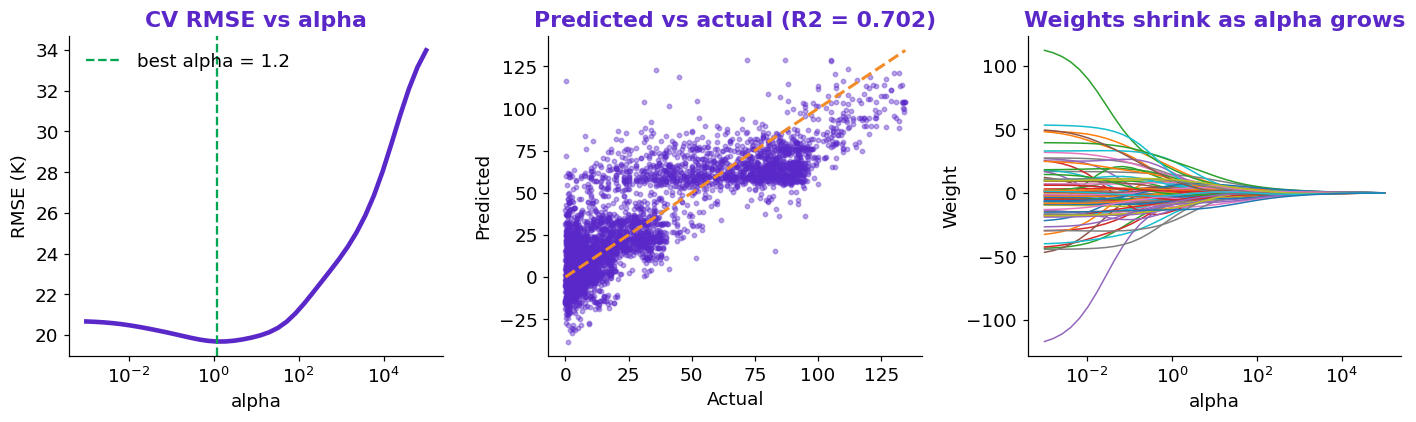

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(13, 4))

ax[0].semilogx(alphas, cv_rmse, color=PURPLE, lw=3)
ax[0].axvline(best_alpha, color=GREEN, ls="--", label=f"best alpha = {best_alpha:.2g}")
ax[0].set(title="CV RMSE vs alpha", xlabel="alpha", ylabel="RMSE (K)")
ax[0].legend()
ax[2].semilogx(alphas, paths, lw=1)
ax[2].set(title="Weights shrink as alpha grows", xlabel="alpha", ylabel="Weight")

ax[1].scatter(y_test, y_pred, s=8, alpha=0.4, color=PURPLE)
limits = [y_test.min(), y_test.max()]
ax[1].plot(limits, limits, "--", color=ORANGE, lw=2)
ax[1].set(title=f"Predicted vs actual (R2 = {r2:.3f})", xlabel="Actual", ylabel="Predicted")
fig.tight_layout()
plt.show()

In [8]:
# SAVE THE RESULTS. The figure and the metrics are written to a "results" folder.
# These exact files are what the course slides show.
import json

results_dir = Path("results")
results_dir.mkdir(exist_ok=True)
fig.savefig(results_dir / "13_ridge_regression.png", dpi=170, bbox_inches="tight", facecolor="white")

results = {
    "model": "Ridge Regression",
    "dataset": "Superconductivity (UCI)",
    "n_samples": int(len(df)),
    "metrics": {"RMSE (K)": round(rmse, 2), "R2": round(r2, 4), "OLS RMSE (K)": round(ols_rmse, 2), "Best alpha": round(best_alpha, 3)},
}
(results_dir / "13_ridge_regression.json").write_text(json.dumps(results, indent=2), encoding="utf-8")
print(json.dumps(results, indent=2))

{
  "model": "Ridge Regression",
  "dataset": "Superconductivity (UCI)",
  "n_samples": 21263,
  "metrics": {
    "RMSE (K)": 18.53,
    "R2": 0.7018,
    "OLS RMSE (K)": 19.12,
    "Best alpha": 1.194
  }
}


## What to remember
- A larger alpha means a simpler model.
- Ridge keeps every feature, only with smaller weights.